# E-Commerce Sales Data Analysis



## 1. Understand our project


Objective: Analyze e-commerce orders to understand sales performance,profitability,
customer purchasing patterns, payment preferences and delivery performance.

Dataset: ecommerce_dataset_6000.csv

## 2. Our project roadmap

##### 1 Import libraries and load dataset
##### 2 Initial data exploration – rows, columns, data types and statistics.
##### 3 Data cleaning – missing values, duplicates and incorrect data types.
##### 4 Feature engineering – create useful new columns.
##### 5 Exploratory data analysis – sales, profit, orders and customers.
##### 6 10+ visualizations using Matplotlib, Seaborn and Plotly.
##### 7 Business insights and recommendations 
##### 8 Final report and notebook preparation.

 #### 1. Import Python libraries

In [2]:


import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
pip install plotly

Note: you may need to restart the kernel to use updated packages.


#### 2.Upload and load the dataset

In [4]:
import pandas as pd

df = pd.read_csv(r"C:\Users\HP\Downloads\ecommerce_dataset_6000.csv")

print("Dataset loaded successfully!")


Dataset loaded successfully!


#### 3.Display the first five records

In [5]:
df.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,sales,profit,payment_method,ship_mode,order_status
0,ORD100001,06-03-2024,CUST01742,PROD0536,4,5520.17,0.10,19872.61,9409.99,UPI,Standard,Shipped
1,ORD100002,18-07-2025,CUST04092,PROD0523,5,1514.41,0.05,7193.45,1786.04,Debit Card,Standard,Delivered
2,ORD100003,22-04-2025,CUST02329,PROD0422,4,6873.16,0.00,27492.64,5059.11,COD,Express,Delivered
3,ORD100004,16-11-2024,CUST03154,PROD0390,3,1961.50,0.30,4119.15,1637.23,Debit Card,Standard,Delivered
4,ORD100005,12-11-2024,CUST04635,PROD0296,3,825.40,0.00,2476.20,559.08,Credit Card,Same-Day,Delivered


#### 4.Check dataset dimensions

In [5]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Number of rows: 6000
Number of columns: 12


This is the shape of our data set which contain 12 columns and 6000 rows

#### 5.Check dataset information

In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   order_id        6000 non-null   str    
 1   order_date      6000 non-null   str    
 2   customer_id     6000 non-null   str    
 3   product_id      6000 non-null   str    
 4   quantity        6000 non-null   int64  
 5   unit_price      6000 non-null   float64
 6   discount        6000 non-null   float64
 7   sales           6000 non-null   float64
 8   profit          6000 non-null   float64
 9   payment_method  6000 non-null   str    
 10  ship_mode       6000 non-null   str    
 11  order_status    6000 non-null   str    
dtypes: float64(4), int64(1), str(7)
memory usage: 562.6 KB


#### 6.Statistical summary

In [10]:
df.describe()

,quantity,unit_price,discount,sales,profit
count,6000.000000,6000.000000,6000.000000,6000.000000,6000.000000
mean,2.985333,6059.025388,0.112492,16032.709942,5569.935198
std,1.400516,3425.916896,0.087330,12620.169729,4779.559426
min,1.000000,100.160000,0.000000,103.960000,22.080000
25%,2.000000,3072.612500,0.050000,6004.855000,1939.147500
50%,3.000000,6120.675000,0.100000,12430.770000,4215.210000
75%,4.000000,8955.975000,0.200000,23787.587500,7900.600000
max,5.000000,11999.730000,0.300000,59866.550000,28610.810000


## Step 2 – Data cleaning and preprocessing

#### Now we need to check whether our dataset contains missing values,
#### duplicate records or incorrect data types

#### 1.Check missing values

In [11]:
df.isnull().sum()

order_id          0
order_date        0
customer_id       0
product_id        0
quantity          0
unit_price        0
discount          0
sales             0
profit            0
payment_method    0
ship_mode         0
order_status      0
dtype: int64

We can see there is no missing values found.
    so lets continue

#### 2.Check duplicate records

In [12]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In this dataframe there is no duplicate rows found

#### 3.Check data types

In [13]:
df.dtypes

order_id              str
order_date            str
customer_id           str
product_id            str
quantity            int64
unit_price        float64
discount          float64
sales             float64
profit            float64
payment_method        str
ship_mode             str
order_status          str
dtype: object

here we can see all the data type of the columns
We need to change order date to date format

 #### Convert order_date into datetime

In [14]:
df['order_date'] = pd.to_datetime(
    df['order_date'],
    format='%d-%m-%Y',
    errors='coerce'
)

df.dtypes

order_id                     str
order_date        datetime64[us]
customer_id                  str
product_id                   str
quantity                   int64
unit_price               float64
discount                 float64
sales                    float64
profit                   float64
payment_method               str
ship_mode                    str
order_status                 str
dtype: object

Date format is now set

#### Now lets check the updated dataset

In [15]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6000 entries, 0 to 5999
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   order_id        6000 non-null   str           
 1   order_date      6000 non-null   datetime64[us]
 2   customer_id     6000 non-null   str           
 3   product_id      6000 non-null   str           
 4   quantity        6000 non-null   int64         
 5   unit_price      6000 non-null   float64       
 6   discount        6000 non-null   float64       
 7   sales           6000 non-null   float64       
 8   profit          6000 non-null   float64       
 9   payment_method  6000 non-null   str           
 10  ship_mode       6000 non-null   str           
 11  order_status    6000 non-null   str           
dtypes: datetime64[us](1), float64(4), int64(1), str(6)
memory usage: 562.6 KB


#### Now we'll create additional columns to make our analysis more useful.

In [16]:
df['year'] = df['order_date'].dt.year

df.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,sales,profit,payment_method,ship_mode,order_status,year
0,ORD100001,2024-03-06,CUST01742,PROD0536,4,5520.17,0.10,19872.61,9409.99,UPI,Standard,Shipped,2024
1,ORD100002,2025-07-18,CUST04092,PROD0523,5,1514.41,0.05,7193.45,1786.04,Debit Card,Standard,Delivered,2025
2,ORD100003,2025-04-22,CUST02329,PROD0422,4,6873.16,0.00,27492.64,5059.11,COD,Express,Delivered,2025
3,ORD100004,2024-11-16,CUST03154,PROD0390,3,1961.50,0.30,4119.15,1637.23,Debit Card,Standard,Delivered,2024
4,ORD100005,2024-11-12,CUST04635,PROD0296,3,825.40,0.00,2476.20,559.08,Credit Card,Same-Day,Delivered,2024


Now we extracted and added new column "Year"

In [17]:
df['month'] = df['order_date'].dt.month

df['month_name'] = df['order_date'].dt.month_name()

df.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,sales,profit,payment_method,ship_mode,order_status,year,month,month_name
0,ORD100001,2024-03-06,CUST01742,PROD0536,4,5520.17,0.10,19872.61,9409.99,UPI,Standard,Shipped,2024,3,March
1,ORD100002,2025-07-18,CUST04092,PROD0523,5,1514.41,0.05,7193.45,1786.04,Debit Card,Standard,Delivered,2025,7,July
2,ORD100003,2025-04-22,CUST02329,PROD0422,4,6873.16,0.00,27492.64,5059.11,COD,Express,Delivered,2025,4,April
3,ORD100004,2024-11-16,CUST03154,PROD0390,3,1961.50,0.30,4119.15,1637.23,Debit Card,Standard,Delivered,2024,11,November
4,ORD100005,2024-11-12,CUST04635,PROD0296,3,825.40,0.00,2476.20,559.08,Credit Card,Same-Day,Delivered,2024,11,November


Now we extracted and added new column "Month"

In [18]:
df['order_day'] = df['order_date'].dt.day_name()

df.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,sales,profit,payment_method,ship_mode,order_status,year,month,month_name,order_day
0,ORD100001,2024-03-06,CUST01742,PROD0536,4,5520.17,0.10,19872.61,9409.99,UPI,Standard,Shipped,2024,3,March,Wednesday
1,ORD100002,2025-07-18,CUST04092,PROD0523,5,1514.41,0.05,7193.45,1786.04,Debit Card,Standard,Delivered,2025,7,July,Friday
2,ORD100003,2025-04-22,CUST02329,PROD0422,4,6873.16,0.00,27492.64,5059.11,COD,Express,Delivered,2025,4,April,Tuesday
3,ORD100004,2024-11-16,CUST03154,PROD0390,3,1961.50,0.30,4119.15,1637.23,Debit Card,Standard,Delivered,2024,11,November,Saturday
4,ORD100005,2024-11-12,CUST04635,PROD0296,3,825.40,0.00,2476.20,559.08,Credit Card,Same-Day,Delivered,2024,11,November,Tuesday


Now we extract and added new column "Order day of week"

#### Profit margin

In [19]:
df['profit_margin'] = (
    df['profit'] / df['sales']
) * 100

df.head()

,order_id,order_date,customer_id,product_id,quantity,unit_price,discount,sales,profit,payment_method,ship_mode,order_status,year,month,month_name,order_day,profit_margin
0,ORD100001,2024-03-06,CUST01742,PROD0536,4,5520.17,0.10,19872.61,9409.99,UPI,Standard,Shipped,2024,3,March,Wednesday,47.351556
1,ORD100002,2025-07-18,CUST04092,PROD0523,5,1514.41,0.05,7193.45,1786.04,Debit Card,Standard,Delivered,2025,7,July,Friday,24.828698
2,ORD100003,2025-04-22,CUST02329,PROD0422,4,6873.16,0.00,27492.64,5059.11,COD,Express,Delivered,2025,4,April,Tuesday,18.401689
3,ORD100004,2024-11-16,CUST03154,PROD0390,3,1961.50,0.30,4119.15,1637.23,Debit Card,Standard,Delivered,2024,11,November,Saturday,39.746792
4,ORD100005,2024-11-12,CUST04635,PROD0296,3,825.40,0.00,2476.20,559.08,Credit Card,Same-Day,Delivered,2024,11,November,Tuesday,22.578144


##### New profit margin colimn added 
##### now we can get to know how much percentage profit we earned on each sales

#### Check the new columns

In [20]:
print("Updated Dataset Shape:", df.shape)

df[['order_date', 'year', 'month',
    'month_name', 'order_day',
    'sales', 'profit', 'profit_margin']].head(10)

Updated Dataset Shape: (6000, 17)


,order_date,year,month,month_name,order_day,sales,profit,profit_margin
0,2024-03-06,2024,3,March,Wednesday,19872.61,9409.99,47.351556
1,2025-07-18,2025,7,July,Friday,7193.45,1786.04,24.828698
2,2025-04-22,2025,4,April,Tuesday,27492.64,5059.11,18.401689
3,2024-11-16,2024,11,November,Saturday,4119.15,1637.23,39.746792
4,2024-11-12,2024,11,November,Tuesday,2476.20,559.08,22.578144
5,2025-09-18,2025,9,September,Thursday,11464.88,2989.29,26.073452
6,2024-03-03,2024,3,March,Sunday,15007.99,3152.59,21.006077
7,2025-05-24,2025,5,May,Saturday,30793.05,11569.36,37.571335
8,2024-05-27,2024,5,May,Monday,7532.59,3657.51,48.555809
9,2024-03-09,2024,3,March,Saturday,9271.04,4447.86,47.975847


here we get all the columns we added by top 10 rows 

### Exploratory Data Analysis (EDA)

##### EDA means Exploratory Data Analysis. We analyze the dataset to discover patterns,
##### trends and useful business information

#### Verify updated dataset

In [21]:
print("Dataset Shape:", df.shape)
print("\nColumn Names:")
print(df.columns.tolist())

Dataset Shape: (6000, 17)

Column Names:
['order_id', 'order_date', 'customer_id', 'product_id', 'quantity', 'unit_price', 'discount', 'sales', 'profit', 'payment_method', 'ship_mode', 'order_status', 'year', 'month', 'month_name', 'order_day', 'profit_margin']


#### Overall Sales and Profit Analysis

Now lets have a overall look on our profit and all summary

In [22]:
total_sales = df['sales'].sum()
total_profit = df['profit'].sum()
total_orders = df['order_id'].nunique()
total_customers = df['customer_id'].nunique()
total_products = df['product_id'].nunique()
average_sales = df['sales'].mean()

In [23]:
print("Total Sales:", round(total_sales, 2))
print("Total Profit:", round(total_profit, 2))
print("Total Orders:", total_orders)
print("Total Customers:", total_customers)
print("Total Products:", total_products)
print("Average Sales per Order:", round(average_sales, 2))

Total Sales: 96196259.65
Total Profit: 33419611.19
Total Orders: 6000
Total Customers: 3089
Total Products: 801
Average Sales per Order: 16032.71


### Sales Analysis by Year

In [24]:
yearly_sales = df.groupby('year')['sales'].sum()

print(yearly_sales)

year
2024    48044716.54
2025    48151543.11
Name: sales, dtype: float64


#### Visualize yearly sales

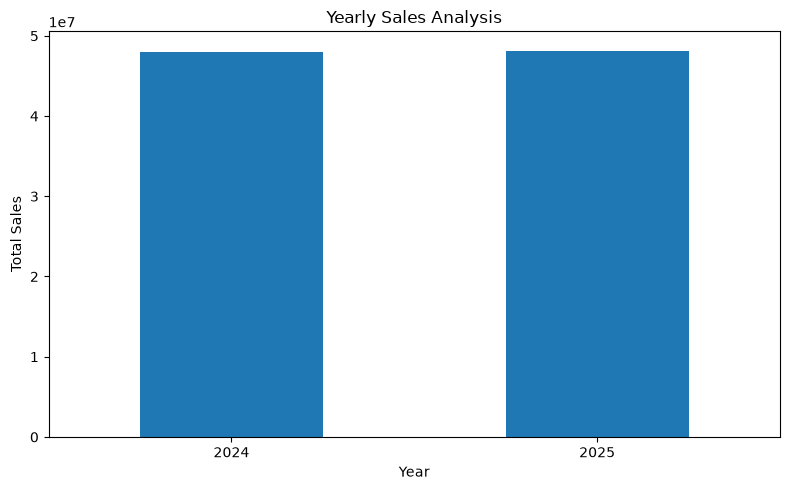

In [25]:
plt.figure(figsize=(8,5))

yearly_sales.plot(kind='bar')

plt.title('Yearly Sales Analysis')
plt.xlabel('Year')
plt.ylabel('Total Sales')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

##### Here we get the total yearly sale by Bar Chart
##### Sales in 2024 and 2025 appear nearly equal, with 2025 slightly higher.

### Monthly Sales Analysis

In [26]:
monthly_sales = df.groupby('month_name')['sales'].sum()

month_order = [
    'January', 'February', 'March', 'April',
    'May', 'June', 'July', 'August',
    'September', 'October', 'November', 'December'
]

monthly_sales = monthly_sales.reindex(month_order)

print(monthly_sales)

month_name
January      8384860.72
February     7287566.36
March        8526558.31
April        7966356.18
May          8031620.73
June         7880864.29
July         8546004.15
August       7889331.54
September    7925579.46
October      6933005.32
November     8244019.58
December     8580493.01
Name: sales, dtype: float64


#### Monthly sales chart

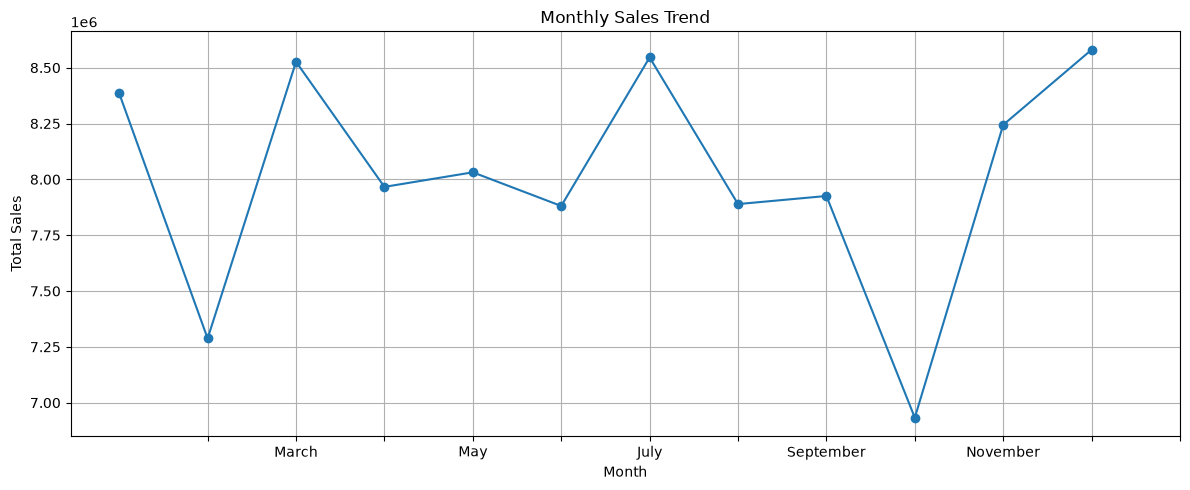

In [27]:
plt.figure(figsize=(12,5))

monthly_sales.plot(kind='line', marker='o')

plt.title('Monthly Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(range(1,13))
plt.grid(True)

plt.tight_layout()
plt.show()


##### Now we can see which month had high sales and low sales
##### December has the highest combined sales, approximately 8.6 million.
##### October has the lowest combined sales, approximately 6.9 million.

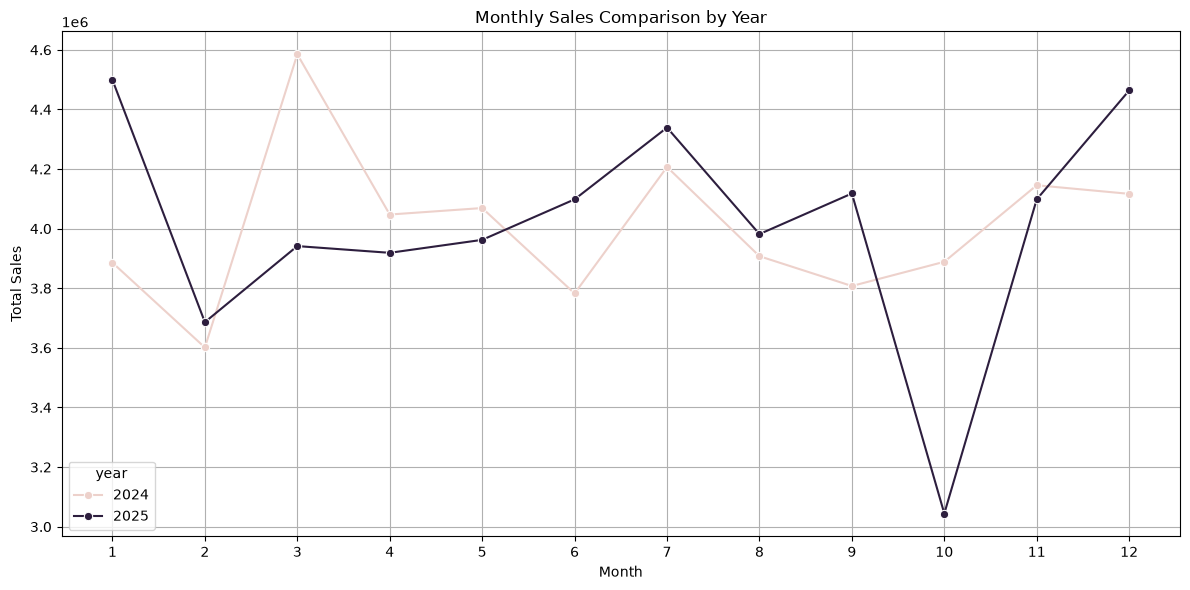

In [28]:
monthly_yearly_sales = df.groupby(
    ['year', 'month']
)['sales'].sum().reset_index()

plt.figure(figsize=(12,6))

sns.lineplot(
    data=monthly_yearly_sales,
    x='month',
    y='sales',
    hue='year',
    marker='o'
)

plt.title('Monthly Sales Comparison by Year')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(range(1,13))
plt.grid(True)

plt.tight_layout()

##### This chart compares monthly sales performance between 2024 and 2025.
##### March 2024 shows a strong sales peak, while October 2025 shows a noticeable decline.

### Profitability Analysis

##### Now we'll analyze how much profit the business generates.

In [29]:
yearly_profit = df.groupby('year')['profit'].sum()

print(yearly_profit)

year
2024    16740627.05
2025    16678984.14
Name: profit, dtype: float64


### Yearly profit bar chart

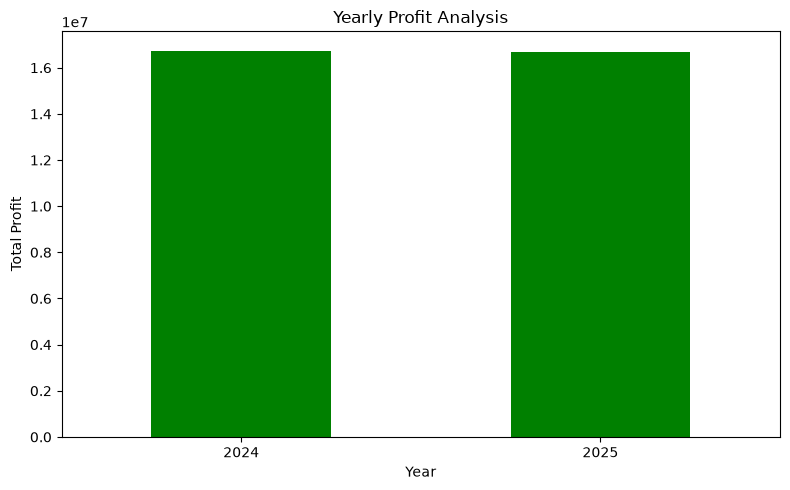

In [30]:
plt.figure(figsize=(8,5))

yearly_profit.plot(kind='bar', color='green')

plt.title('Yearly Profit Analysis')
plt.xlabel('Year')
plt.ylabel('Total Profit')
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

#### Profit in 2024 and 2025 is almost equal.

### Monthly profit analysis

In [31]:
monthly_profit = df.groupby('month')['profit'].sum()

print(monthly_profit)

month
1     2902967.79
2     2524657.41
3     2960508.28
4     2739342.44
5     2794637.66
6     2762216.94
7     3017818.15
8     2687237.43
9     2812962.05
10    2343991.65
11    2881229.78
12    2992041.61
Name: profit, dtype: float64


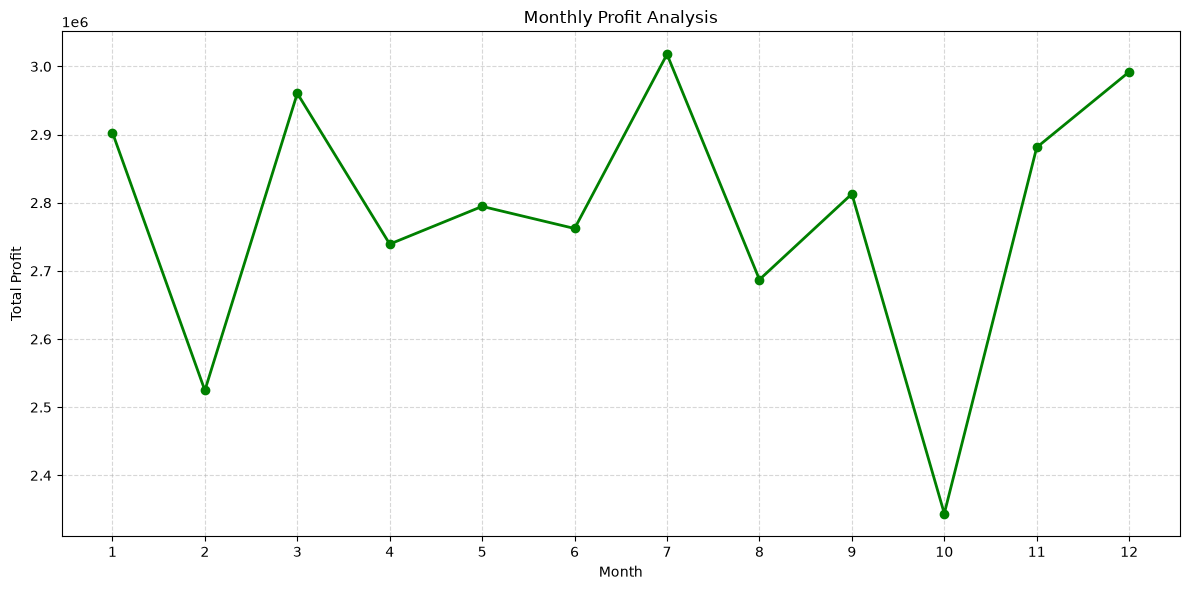

In [32]:
monthly_profit = df.groupby('month')['profit'].sum()
plt.figure(figsize=(12, 6))

plt.plot(
    monthly_profit.index,
    monthly_profit.values,
    color='green',
    marker='o',
    linewidth=2
)
plt.title('Monthly Profit Analysis')
plt.xlabel('Month')
plt.ylabel('Total Profit')
plt.xticks(range(1, 13))
plt.grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

##### July has the highest combined profit, approximately 3.02 million.
##### October has the lowest combined profit, approximately 2.34 million.

### Sales vs Profit comparison

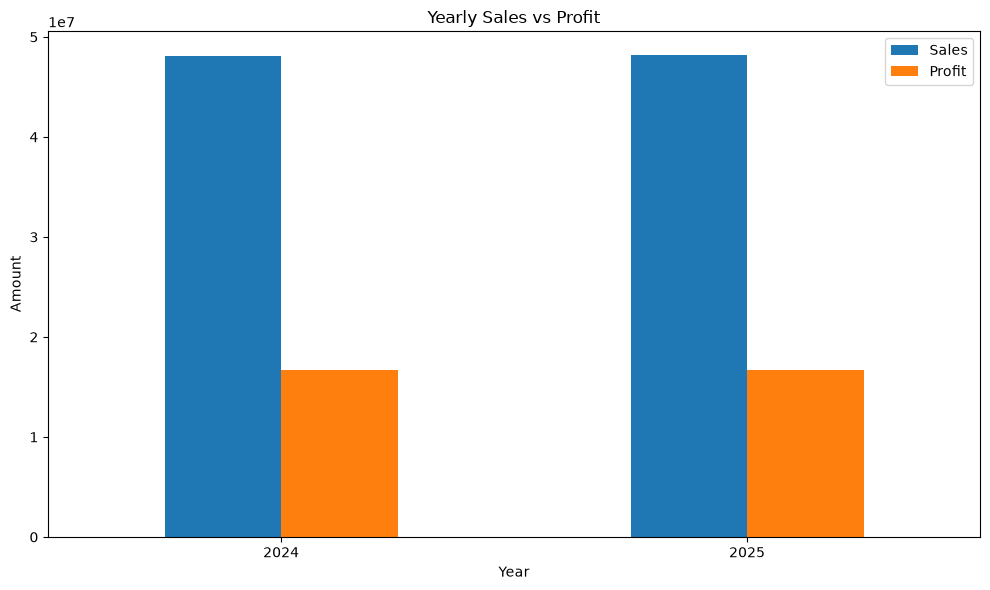

In [33]:
sales_profit = df.groupby('year')[['sales', 'profit']].sum()

sales_profit.plot(
    kind='bar',
    figsize=(10,6)
)

plt.title('Yearly Sales vs Profit')
plt.xlabel('Year')
plt.ylabel('Amount')
plt.xticks(rotation=0)
plt.legend(['Sales', 'Profit'])

plt.tight_layout()
plt.show()

#### Sales are substantially higher than profit in both years.

### Count payment methods

In [34]:
payment_counts = df['payment_method'].value_counts()
  
print(payment_counts)

payment_method
COD            1041
Credit Card    1009
UPI             992
Debit Card      991
Net Banking     986
Wallet          981
Name: count, dtype: int64


This shows the number of orders using each payment method.

### Payment Method Pie Chart

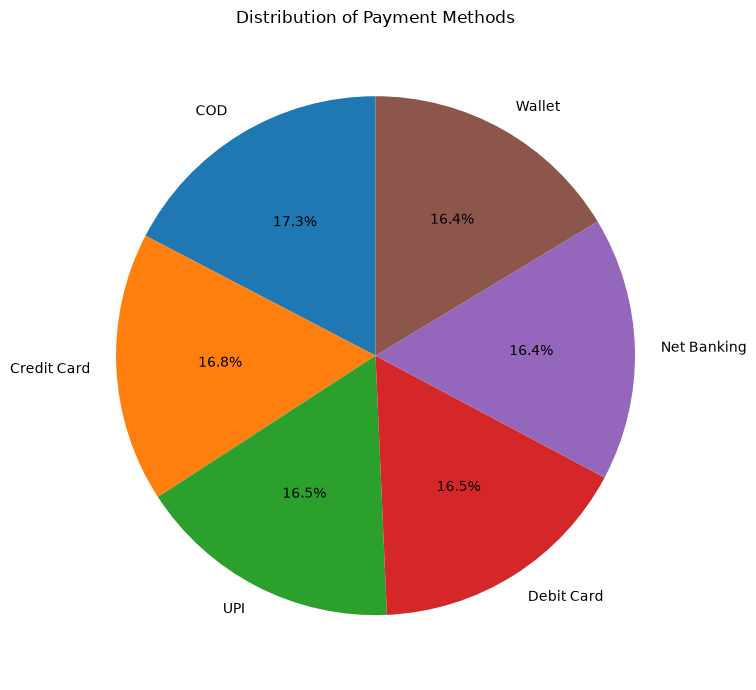

In [35]:
plt.figure(figsize=(9, 7))

plt.pie(
    payment_counts,
    labels=payment_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Distribution of Payment Methods')

plt.tight_layout()
plt.show()

#### The pie chart shows the percentage of orders made using UPI, Credit Card, Debit Card, COD and other payment methods.
#### COD has the highest share at 17.3%, but all six methods are used at similar rates.

### Count shipping modes

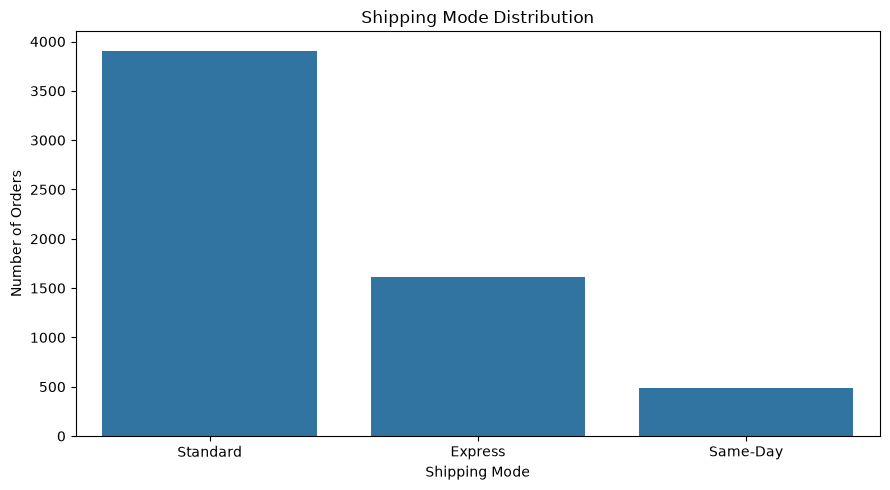

In [36]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x='ship_mode',
    order=df['ship_mode'].value_counts().index
)

plt.title('Shipping Mode Distribution')
plt.xlabel('Shipping Mode')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

#### This chart helps identify the most frequently used shipping method
#### Standard shipping is the most frequently used method, with approximately 3,900 orders.

### Count order statuses

In [37]:
order_status_counts = df['order_status'].value_counts()

print(order_status_counts)

order_status
Delivered    4632
Shipped       621
Cancelled     432
Returned      315
Name: count, dtype: int64


### Order Status Bar Chart

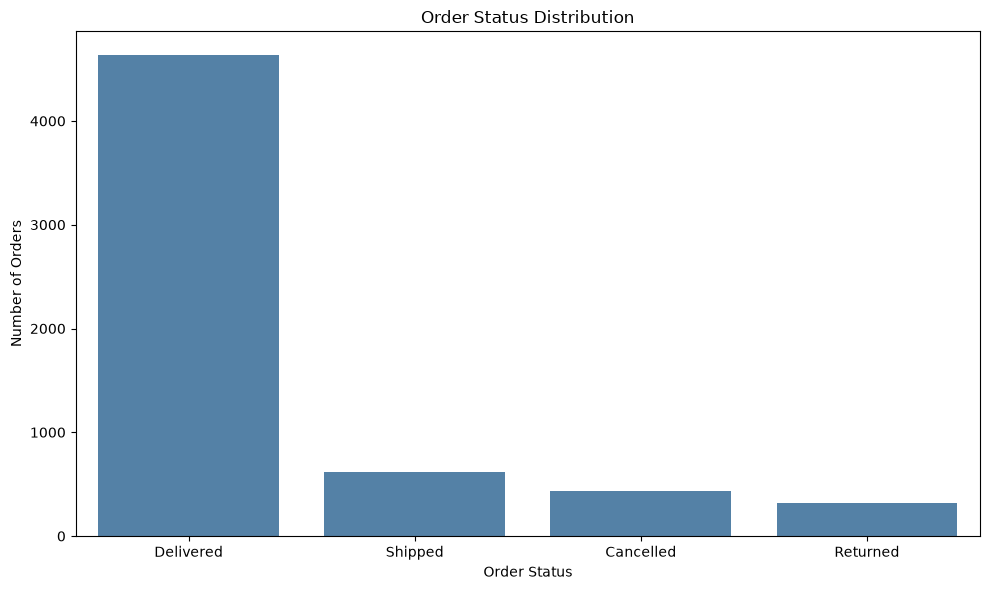

In [38]:
plt.figure(figsize=(10, 6))

sns.countplot(
    data=df,
    x='order_status',
    order=df['order_status'].value_counts().index,
    color='steelblue'
)

plt.title('Order Status Distribution')
plt.xlabel('Order Status')
plt.ylabel('Number of Orders')

plt.tight_layout()
plt.show()

#### Delivered is the most common status, with approximately 4,600 orders.

### Correlation matrix

In [39]:
correlation_data = df[
    ['quantity', 'unit_price', 'discount',
     'sales', 'profit', 'profit_margin']
]

correlation_matrix = correlation_data.corr()

print(correlation_matrix)

               quantity  unit_price  discount     sales    profit  \
quantity       1.000000   -0.006473 -0.003749  0.592232  0.540062   
unit_price    -0.006473    1.000000 -0.008150  0.710693  0.646771   
discount      -0.003749   -0.008150  1.000000 -0.131093 -0.117683   
sales          0.592232    0.710693 -0.131093  1.000000  0.909152   
profit         0.540062    0.646771 -0.117683  0.909152  1.000000   
profit_margin -0.011785   -0.005930  0.004664 -0.018235  0.309611   

               profit_margin  
quantity           -0.011785  
unit_price         -0.005930  
discount            0.004664  
sales              -0.018235  
profit              0.309611  
profit_margin       1.000000  


### Correlation Heatmap

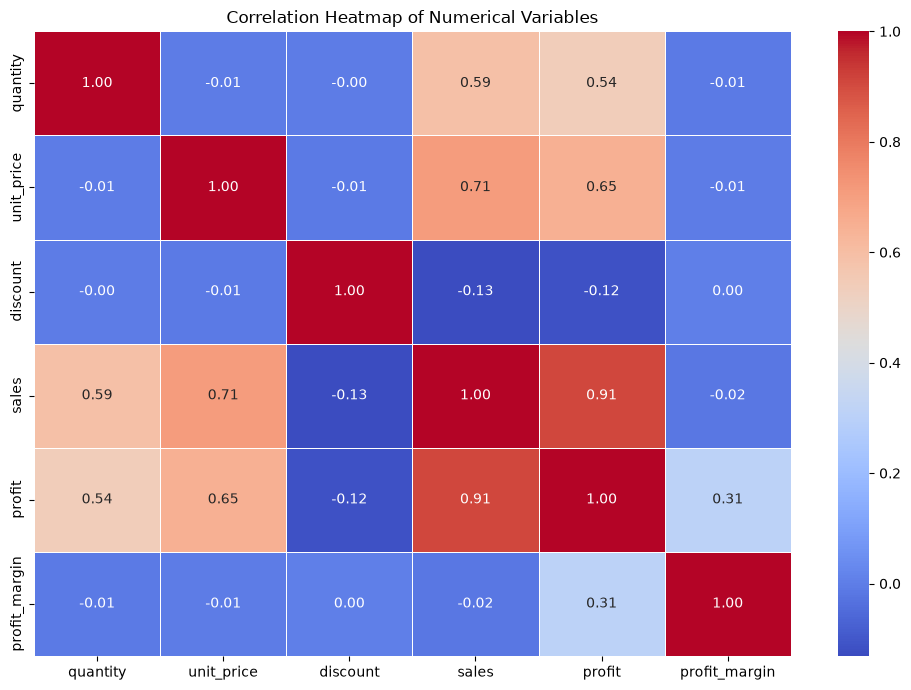

In [40]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Numerical Variables')

plt.tight_layout()
plt.show()

#### Sales vs Profit	Strong positive correlation of 0.91.
#### Discount vs Sales	Weak negative correlation of -0.13.
#### Profit vs Profit Margin	Positive correlation of 0.31.

### Customer Purchase Analysis

In [41]:
customer_analysis = df.groupby('customer_id').agg(
    total_orders=('order_id', 'nunique'),
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum')
)
top_customers = customer_analysis.sort_values(
    by='total_sales',
    ascending=False
).head(10)

print(top_customers)

             total_orders  total_sales  total_profit
customer_id                                         
CUST02694               8    198977.63      58340.50
CUST02505               6    193902.24      83125.88
CUST03447               6    169919.39      42812.58
CUST01434               5    166293.19      63341.30
CUST01115               6    158803.49      61142.93
CUST04504               5    155984.01      47429.92
CUST03849               5    155467.60      61367.79
CUST01572               5    151879.80      34331.33
CUST03251               4    146124.22      49204.76
CUST03186               5    144779.80      49188.20


#### Customer CUST02694 generated the highest sales among customers, with 8 orders totaling 198,977.63.

### Payment Method Sales Analysis

In [42]:
payment_sales = df.groupby('payment_method').agg(
    total_orders=('order_id', 'nunique'),
    total_sales=('sales', 'sum'),
    total_profit=('profit', 'sum')
)

print(payment_sales)

                total_orders  total_sales  total_profit
payment_method                                         
COD                     1041  16599775.09    5773093.26
Credit Card             1009  16564564.56    5732002.14
Debit Card               991  16327890.55    5624281.48
Net Banking              986  15257603.55    5277506.11
UPI                      992  15753586.62    5508037.29
Wallet                   981  15692839.28    5504690.91


#### 	COD generated approximately 16.6 million in sales, slightly higher than Credit Card

### Pivot Table Analysis

In [43]:
sales_pivot = pd.pivot_table(
    df,
    values='sales',
    index='year',
    columns='month',
    aggfunc='sum',
    fill_value=0
)

print(sales_pivot)

month          1           2           3           4           5           6   \
year                                                                            
2024   3885829.10  3601295.41  4585053.41  4047418.00  4069170.32  3782557.96   
2025   4499031.62  3686270.95  3941504.90  3918938.18  3962450.41  4098306.33   

month          7           8           9           10          11          12  
year                                                                           
2024   4206912.17  3907563.71  3807582.07  3888849.00  4145641.85  4116843.54  
2025   4339091.98  3981767.83  4117997.39  3044156.32  4098377.73  4463649.47  


### Key Business Insights

#### Insight 1: Customer Purchase Behavior

Customer CUST02694 recorded the highest total purchase value of 198,977.63 across 8 orders. This indicates that repeat customers can make a significant contribution to total sales.

#### Insight 2: Payment Method Preferences

Cash on Delivery (COD) accounted for approximately 17.3% of orders and generated around 16.6 million in sales. However, the distribution across payment methods was relatively balanced.

#### Insight 3: Yearly Sales Performance

Sales performance remained relatively stable between 2024 and 2025, with only a small difference in total revenue.

#### Insight 4: Monthly Sales Trends

December recorded the highest combined sales, while October recorded the lowest. This suggests that sales performance varies across months.

#### Insight 5: Profitability Analysis

July generated the highest combined monthly profit, approximately 3.02 million, while October recorded the lowest, approximately 2.34 million.

#### Insight 6: Sales and Profit Correlation

The correlation coefficient between sales and profit was 0.91, indicating a strong positive relationship. Orders with higher sales values generally tend to generate higher absolute profits.

### Business Recommendations

#### 1.Customer Retention:
Introduce loyalty programs and personalized offers for repeat and high-value customers.

#### 2.Payment Options:
Continue supporting multiple payment methods because customers use them at relatively similar rates.

#### 3.Sales Improvement:
Investigate the reasons for lower sales in October and consider targeted promotional campaigns.

#### 4.Profitability Management:
Monitor profit margins and discount levels to identify opportunities to improve profitability.

#### 5.Shipping Efficiency:
Review Standard shipping performance because it accounts for the largest share of orders.

#### 6.Order Fulfillment:
Analyze cancelled and returned orders to identify potential improvements in customer experience.

### Final Project Conclusion

### Conclusion

This project analyzed an E-Commerce dataset containing 6,000 records and 12 original features using Python.

The analysis included data cleaning, preprocessing, feature engineering, exploratory data analysis, statistical summaries, pivot tables, correlation analysis, and data visualization.

The findings showed that sales and profit remained relatively stable across the two years. December recorded the highest combined monthly sales, while July generated the highest combined monthly profit. October recorded the lowest combined monthly sales and profit.

Customer purchase analysis identified high-value customers, while payment method and shipping mode analysis provided insights into purchasing and fulfillment patterns.

The correlation analysis also revealed a strong positive relationship between sales and profit.

Overall, the project demonstrates how Python-based data analysis can help businesses understand performance, identify trends, and support data-driven decision-making.